In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
!pip install pandas numpy matplotlib seaborn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


Load the dataset

In [4]:
file_path = "HHS_Unaccompanied_Alien_Children_Program.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Original shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Original shape: (1170, 6)


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,"December 21, 2025",6.0,18.0,11.0,"2,484",14.0
1,"December 18, 2025",11.0,50.0,6.0,"2,472",16.0
2,"December 17, 2025",7.0,31.0,11.0,"2,481",10.0
3,"December 16, 2025",8.0,54.0,15.0,"2,468",9.0
4,"December 15, 2025",11.0,42.0,9.0,"2,470",7.0


understand the dataset

In [5]:
print("Column names:")
print(df.columns.tolist())

print("\\nDataset information:")
df.info()

print("\\nFirst statistical summary:")
display(df.describe(include="all"))

Column names:
['Date', 'Children apprehended and placed in CBP custody*', 'Children in CBP custody', 'Children transferred out of CBP custody', 'Children in HHS Care', 'Children discharged from HHS Care']
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1170 entries, 0 to 1169
Data columns (total 6 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   Date                                             720 non-null    object 
 1   Children apprehended and placed in CBP custody*  720 non-null    float64
 2   Children in CBP custody                          720 non-null    float64
 3   Children transferred out of CBP custody          720 non-null    float64
 4   Children in HHS Care                             720 non-null    object 
 5   Children discharged from HHS Care                720 non-null    float64
dtypes: float64(4), object(2)
memory usage

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
count,720,720.000000,720.000000,720.000000,720,720.000000
unique,720,NaN,NaN,NaN,642,NaN
top,"December 21, 2025",NaN,NaN,NaN,"5,963",NaN
freq,1,NaN,NaN,NaN,3,NaN
mean,NaN,93.523611,171.494444,128.668056,NaN,173.406944
std,NaN,72.646625,126.354965,97.322012,NaN,125.702841
min,NaN,0.000000,7.000000,0.000000,NaN,0.000000
25%,NaN,12.000000,36.000000,14.000000,NaN,19.750000
50%,NaN,99.000000,193.000000,157.000000,NaN,181.000000
75%,NaN,147.250000,263.250000,199.250000,NaN,267.000000


Data cleaning

In [ ]:
# Remove completely empty rows
df = df.dropna(how="all").copy()

# Clean column names by removing leading/trailing spaces
df.columns = df.columns.str.strip()

# Convert date column
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Numeric columns
numeric_cols = [
"Childern apprehended and placed in CBP custody*",
"Children in CBP custody",
"Children transferred out of CBP custody",
"Children in HHS Care",
"Children discharged from HHS Care"
]

# Remove commas and convert  values to numeric
for col in numeric_cols:
    df[col] = pd.to_numeric(
       df[col].astype(str).str.replace(","," ", regex = False),
       errors = "coerce"
    )

# Remove rows without a valid date
df = df.dropna(subset = ["Dtae"])

# Sort chronologicallyand remove duplicate dates, if any
df = df.sort_values("Date")
df = df.drop_duplicates(subset=["Date"],
keep = "last").reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("Date range:", df["Date"].min().date(), "to",
df["Date"].max().date())
print("\\nMissing values after cleaning:")
display(df.isnull().sum().to_frame("Missing values"))
display(df.head())


Numpy mumerical analysis

In [16]:
print(df.columns.tolist())

['Date', 'Children apprehended and placed in CBP custody*', 'Children in CBP custody', 'Children transferred out of CBP custody', 'Children in HHS Care', 'Children discharged from HHS Care']


In [19]:
numeric_cols = [
    
    "Children apprehended and placed in CBP custody*"
    "Children in CBP custody",
    "Children transferred out of CBP custody"
    "Children in HHS Care",
    "Children discharged from HHS Care"
]

print(numeric_cols)

['Children apprehended and placed in CBP custody*Children in CBP custody', 'Children transferred out of CBP custodyChildren in HHS Care', 'Children discharged from HHS Care']


In [23]:
print("Actual Dataset Column Names:")
for col in df.columns:
    print(repr(col))

Actual Dataset Column Names:
'Date'
'Children apprehended and placed in CBP custody*'
'Children in CBP custody'
'Children transferred out of CBP custody'
'Children in HHS Care'
'Children discharged from HHS Care'


In [25]:
numeric_cols = [
    
    "Children apprehended and placed in CBP custody*"
    "Children in CBP custody",
    "Children transferred out of CBP custody"
    "Children in HHS Care",
    "Children discharged from HHS Care"
]

print("correct column list:")
for col in numeric_cols:
    print(repr(col))


correct column list:
'Children apprehended and placed in CBP custody*Children in CBP custody'
'Children transferred out of CBP custodyChildren in HHS Care'
'Children discharged from HHS Care'


In [27]:
for col in numeric_cols:
    print(col, ":", col in df.columns)

Children apprehended and placed in CBP custody*Children in CBP custody : False
Children transferred out of CBP custodyChildren in HHS Care : False
Children discharged from HHS Care : True


In [30]:
import pandas as pd
import numpy as np

# Create the correct column list directly
columns_to_analyze = df.columns[1:].tolist()

print("Columns selected:")
print(columns_to_analyze)

# Numpy Statistical Analysis
print("\n_NUMPY STAISTICAL ANALYSIS")

for col in columns_to_analyze:

    values = pd.to_numeric(
       df[col], errors="coerce"
    ).dropna().to_numpy(dtype=float)

    print("\n_Column:", col)

    if len(values) == 0:
        print("No numerical values available.")
        continue

    print("Mean:", round(np.mean(values), 2))
    print("Median:", round(np.median(values), 2))
    print("Maximum:", round(np.max(values), 2))
    print("Minimum:", round(np.min(values), 2))
    print("Standard deviation:", round(np.std(values), 2))

Columns selected:
['Children apprehended and placed in CBP custody*', 'Children in CBP custody', 'Children transferred out of CBP custody', 'Children in HHS Care', 'Children discharged from HHS Care']

_NUMPY STAISTICAL ANALYSIS

_Column: Children apprehended and placed in CBP custody*
Mean: 93.52
Median: 99.0
Maximum: 333.0
Minimum: 0.0
Standard deviation: 72.6

_Column: Children in CBP custody
Mean: 171.49
Median: 193.0
Maximum: 531.0
Minimum: 7.0
Standard deviation: 126.27

_Column: Children transferred out of CBP custody
Mean: 128.67
Median: 157.0
Maximum: 440.0
Minimum: 0.0
Standard deviation: 97.25

_Column: Children in HHS Care
No numerical values available.

_Column: Children discharged from HHS Care
Mean: 173.41
Median: 181.0
Maximum: 505.0
Minimum: 0.0
Standard deviation: 125.62


In [32]:
print("HHS CARE COLUMN DETAILS")

print("\n_First 15 values:")
print(df["Children in HHS Care"].head(15).to_list())

print("\n_Data type:")
print(df["Children in HHS Care"].dtype)

print("\n_Missing values:")
print(df["Children in HHS Care"].isna().sum())

HHS CARE COLUMN DETAILS

_First 15 values:
['2,484', '2,472', '2,481', '2,468', '2,470', '2,462', '2,437', '2,439', '2,443', '2,440', '2,429', '2,418', '2,419', '2,407', '2,410']

_Data type:
object

_Missing values:
0


In [34]:
df["Children in HHS Care"] = pd.to_numeric(
    df["Children in HHS Care"].astype(str).str.replace(",","", regex=False),
    errors="coerce"
)

print(df["Children in HHS Care"].head(15))
print("\n_Data type:", df["Children in HHS Care"].dtype)

0     2484
1     2472
2     2481
3     2468
4     2470
5     2462
6     2437
7     2439
8     2443
9     2440
10    2429
11    2418
12    2419
13    2407
14    2410
Name: Children in HHS Care, dtype: int64

_Data type: int64


In [35]:
print("NUMPY STATISTICAL ANALYSIS")

for col in df.columns[1:]:

    values = pd.to_numeric(
        df[col].astype(str).str.replace(",","", regex=False),
        errors="coerce"
    ).dropna().to_numpy(dtype=float)

    print("\n_Column:", col)

    if len(values) == 0:
        print("No numerical values available.")
        continue

    print("Mean:", round(np.mean(values), 2))
    print("Median:", round(np.median(values), 2))
    print("Maximum:", round(np.max(values), 2))
    print("Minimum:", round(np.min(values), 2))
    print("Standard deviation:", round(np.std(values), 2))

NUMPY STATISTICAL ANALYSIS

_Column: Children apprehended and placed in CBP custody*
Mean: 93.52
Median: 99.0
Maximum: 333.0
Minimum: 0.0
Standard deviation: 72.6

_Column: Children in CBP custody
Mean: 171.49
Median: 193.0
Maximum: 531.0
Minimum: 7.0
Standard deviation: 126.27

_Column: Children transferred out of CBP custody
Mean: 128.67
Median: 157.0
Maximum: 440.0
Minimum: 0.0
Standard deviation: 97.25

_Column: Children in HHS Care
Mean: 6061.28
Median: 6406.5
Maximum: 11516.0
Minimum: 1972.0
Standard deviation: 2831.1

_Column: Children discharged from HHS Care
Mean: 173.41
Median: 181.0
Maximum: 505.0
Minimum: 0.0
Standard deviation: 125.62


In [38]:
print("PEAK WORKLOAD IDENTIFICATION")

# Peak HHS Care
peak_hhs = df.loc[df["Children in HHS Care"].idxmax()]

print("\n_Peak HHS Care:")
print("Date:", peak_hhs["Date"])
print("Children:", peak_hhs["Children in HHS Care"])

# Peak CBP Custody
peak_cbp = df.loc[df["Children in CBP custody"].idxmax()]

print("\n_Peak CBP Custody:")
print("Date:", peak_cbp["Date"])
print("Children:", peak_cbp["Children in CBP custody"])

PEAK WORKLOAD IDENTIFICATION

_Peak HHS Care:
Date: 2023-12-20 00:00:00
Children: 11516

_Peak CBP Custody:
Date: 2024-02-04 00:00:00
Children: 531.0


Yearly Summary

In [42]:
print("YEARLY SUMMARY")

df["Date"] = pd.to_datetime(df["Date"])

df["Year"] = df["Date"].dt.year

yearly_summary = df.groupby("Year").agg({
    "Children apprehended and placed in CBP custody*": "mean",
    "Children in CBP custody": "mean",
    "Children transferred out of CBP custody": "mean",
    "Children in HHS Care": "mean",
    "Children discharged from HHS Care": "mean"
})

display(yearly_summary.round(2))

YEARLY SUMMARY


,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
Year,,,,,
2023,117.63,200.47,157.06,8646.07,288.02
2024,148.07,276.90,209.37,7042.96,205.93
2025,13.03,32.91,16.59,2542.84,28.95


Export Analysis

In [44]:
# Export cleaned dataset
df.to_csv("Cleaned_UAC_Data.csv", index=False)

# Export yearly summary
yearly_summary.to_csv("UAC_Yearly_Summary.csv")

print("Files exported successfully!")

Files exported successfully!


In [45]:
import os
print(os.getcwd())

C:\Users\Soujanya


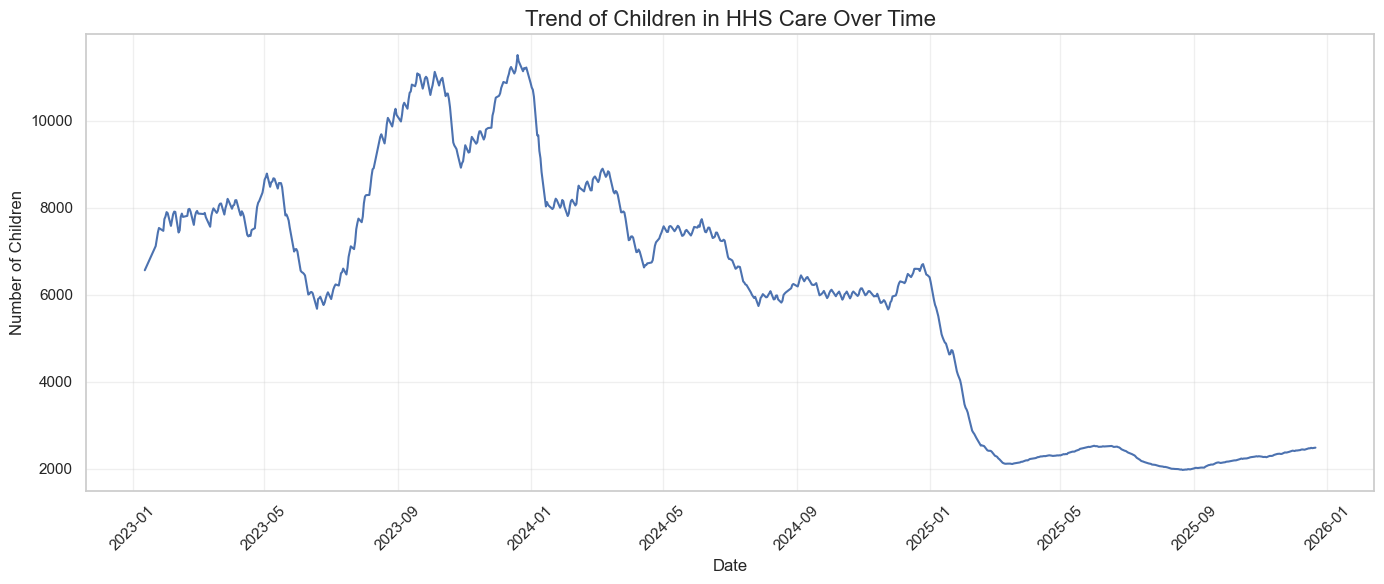

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert Date column
df["Date"] = pd.to_datetime(df["Date"])

# Sort data by date
df = df.sort_values("Date")

# Create chart
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df,
    x="Date",
    y="Children in HHS Care"
)

plt.title("Trend of Children in HHS Care Over Time",
          fontsize=16)

plt.xlabel("Date")
plt.ylabel("Number of Children")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

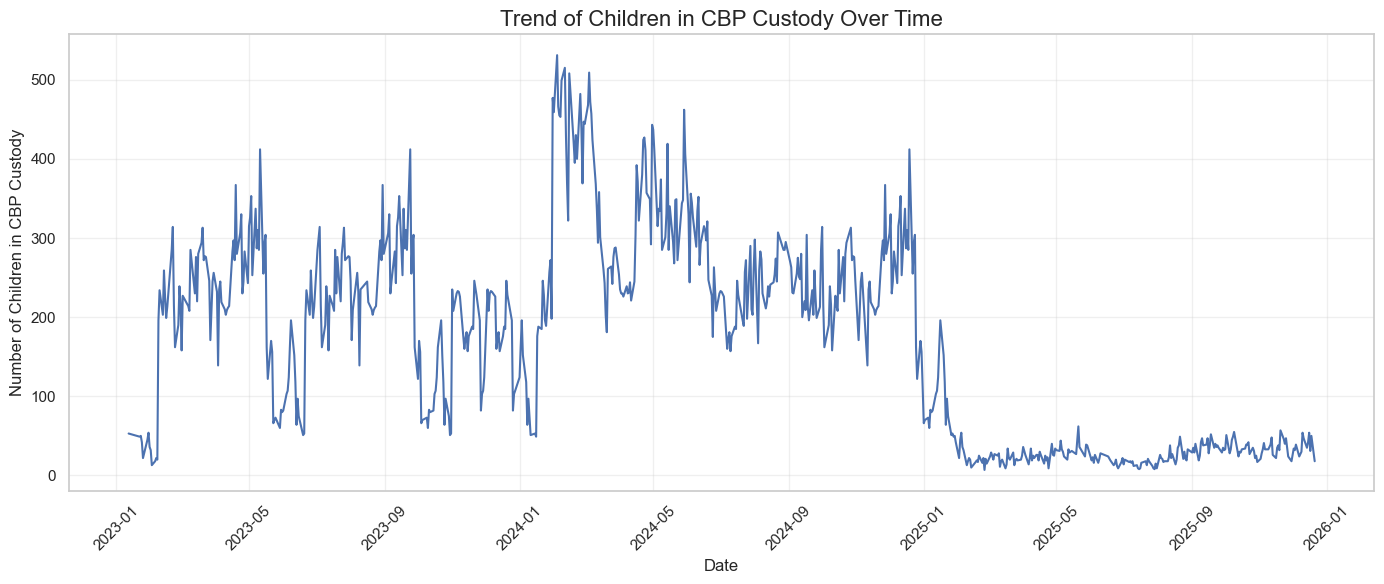

In [47]:
# Chart 2: CBP Custody Trend

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df,
    x="Date",
    y="Children in CBP custody"
)

plt.title("Trend of Children in CBP Custody Over Time",
          fontsize=16)

plt.xlabel("Date")
plt.ylabel("Number of Children in CBP Custody")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

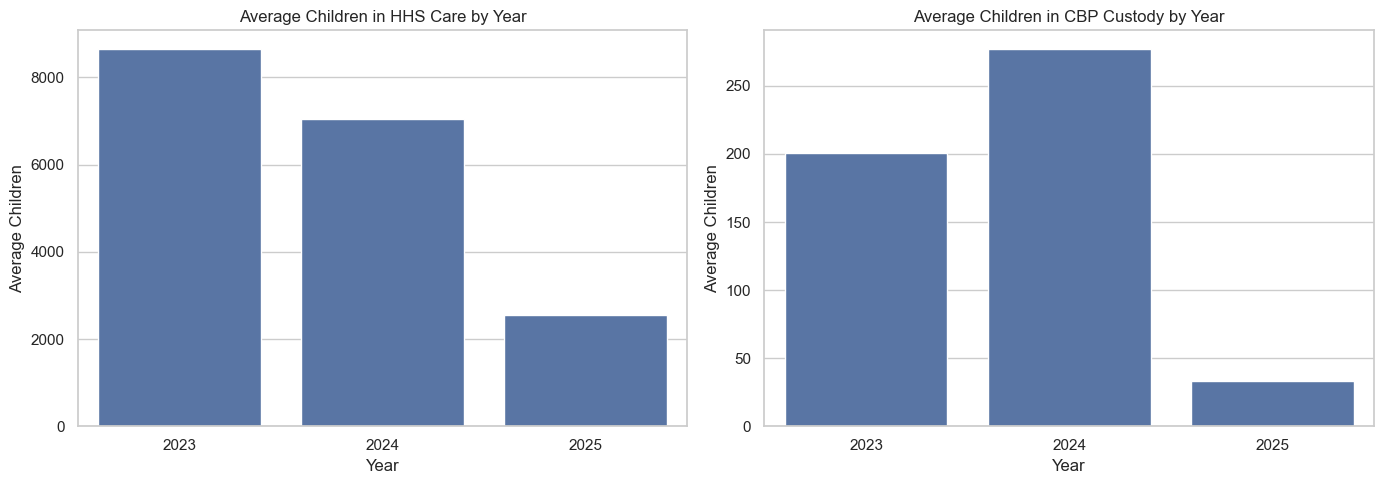

In [48]:
# Chart 3: Yearly Comparison

yearly_data = yearly_summary.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# HHS Care
sns.barplot(
    data=yearly_data,
    x="Year",
    y="Children in HHS Care",
    ax=axes[0]
)

axes[0].set_title("Average Children in HHS Care by Year")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Average Children")

# CBP Custody
sns.barplot(
    data=yearly_data,
    x="Year",
    y="Children in CBP custody",
    ax=axes[1]
)

axes[1].set_title("Average Children in CBP Custody by Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Average Children")

plt.tight_layout()
plt.show()

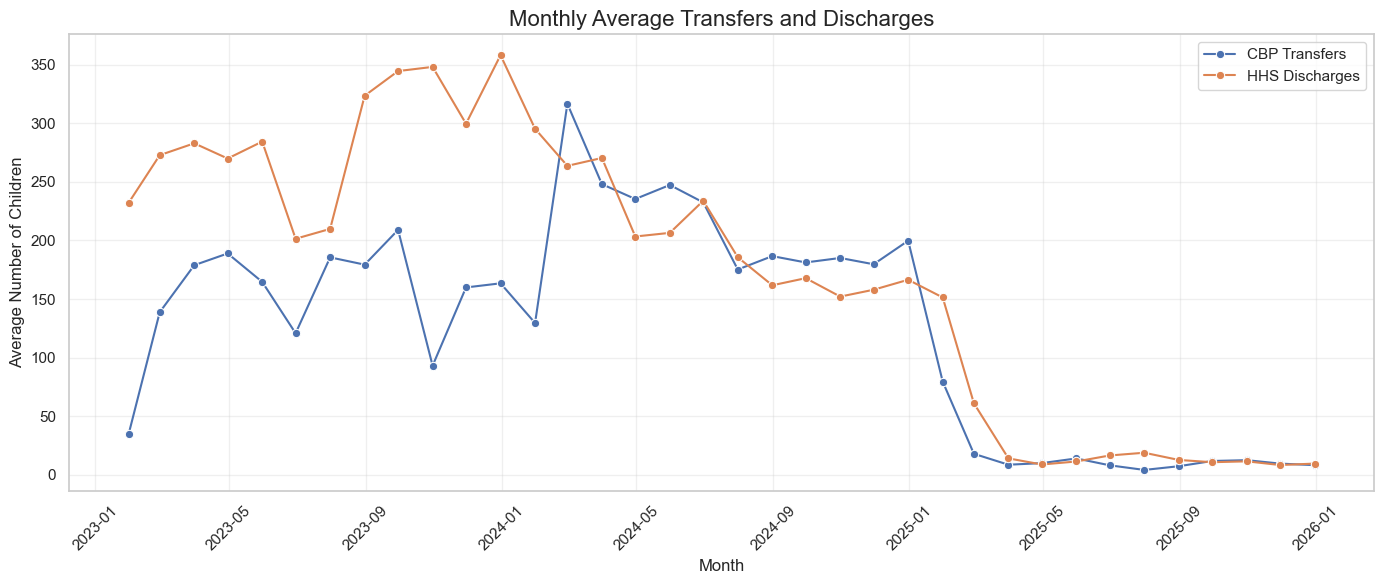

In [49]:
# Chart 4: Monthly Transfers and Discharges

df["Date"] = pd.to_datetime(df["Date"])

monthly_data = df.set_index("Date").resample("ME").agg({
    "Children transferred out of CBP custody": "mean",
    "Children discharged from HHS Care": "mean"
}).reset_index()

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_data,
    x="Date",
    y="Children transferred out of CBP custody",
    label="CBP Transfers",
    marker="o"
)

sns.lineplot(
    data=monthly_data,
    x="Date",
    y="Children discharged from HHS Care",
    label="HHS Discharges",
    marker="o"
)

plt.title("Monthly Average Transfers and Discharges",
          fontsize=16)

plt.xlabel("Month")
plt.ylabel("Average Number of Children")

plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

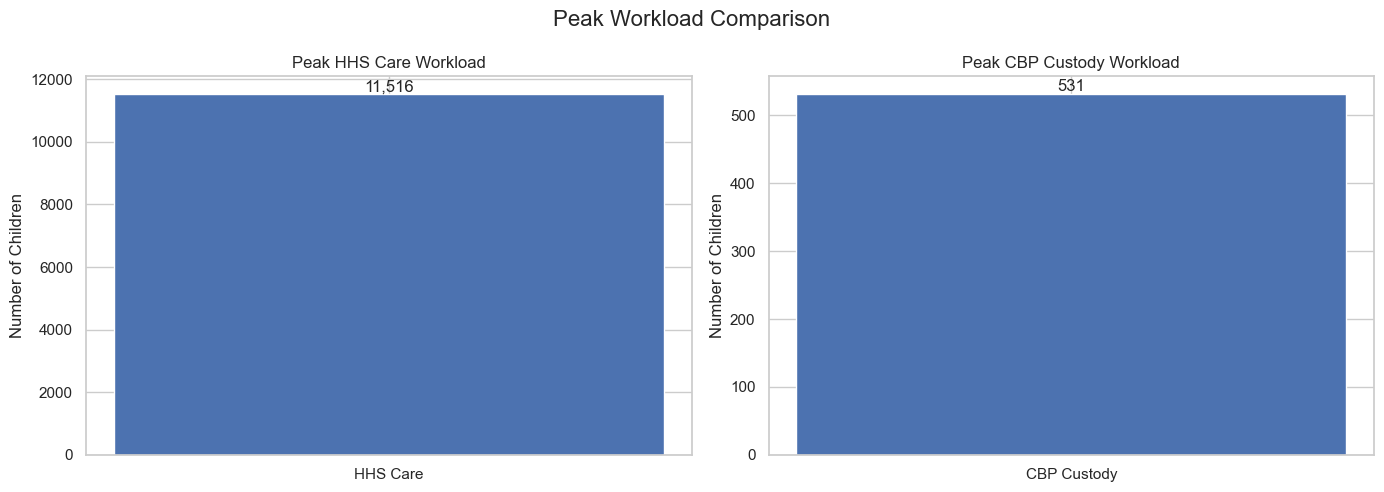

PEAK WORKLOAD DETAILS
HHS Care Date: 2023-12-20 00:00:00
HHS Care Maximum: 11516

CBP Custody Date: 2024-02-04 00:00:00
CBP Custody Maximum: 531


In [50]:
# Chart 5: Peak Workload Comparison

# Find peak records
peak_hhs = df.loc[df["Children in HHS Care"].idxmax()]
peak_cbp = df.loc[df["Children in CBP custody"].idxmax()]

# Create two charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# HHS peak
axes[0].bar(
    ["HHS Care"],
    [peak_hhs["Children in HHS Care"]]
)

axes[0].set_title("Peak HHS Care Workload")
axes[0].set_ylabel("Number of Children")

axes[0].text(
    0,
    peak_hhs["Children in HHS Care"],
    f'{int(peak_hhs["Children in HHS Care"]):,}',
    ha="center",
    va="bottom"
)

# CBP peak
axes[1].bar(
    ["CBP Custody"],
    [peak_cbp["Children in CBP custody"]]
)

axes[1].set_title("Peak CBP Custody Workload")
axes[1].set_ylabel("Number of Children")

axes[1].text(
    0,
    peak_cbp["Children in CBP custody"],
    f'{int(peak_cbp["Children in CBP custody"]):,}',
    ha="center",
    va="bottom"
)

plt.suptitle("Peak Workload Comparison", fontsize=16)
plt.tight_layout()
plt.show()

# Display peak dates and values
print("PEAK WORKLOAD DETAILS")
print("HHS Care Date:", peak_hhs["Date"])
print("HHS Care Maximum:", int(peak_hhs["Children in HHS Care"]))

print("\nCBP Custody Date:", peak_cbp["Date"])
print("CBP Custody Maximum:", int(peak_cbp["Children in CBP custody"]))